# SARGen: an automated, explainable SAR ADC generator in SKY130

**IEEE SSCS Code-a-Chip - ISSCC 2027**

| Name | Affiliation | Contact | IEEE member | SSCS member |
|---|---|---|---|---|
| Rajinthan Rameshkumar | Final-year undergraduate, Dept. of Electronic and Telecommunication Engineering, University of Moratuwa, Sri Lanka | rajinthan519@gmail.com, [rajinthan.com](https://rajinthan.com) | Yes | Yes |

## Abstract
Successive-approximation (SAR) ADCs are the workhorse of low-power data conversion, yet the path from a
specification ("I need N bits at f<sub>s</sub>") to sized transistors is usually hidden in a designer's head.
**SARGen** turns that path into a reproducible, open-source workflow. The user enters the resolution
(4 to 8 bits) and the sample rate; the notebook then

1. **explains** the charge-redistribution binary search with an animation,
2. **characterizes the SKY130 PDK** with ngspice (Pelgrom A<sub>VT</sub>, switch R<sub>on</sub>, MIM density and matching),
3. **sizes every block** from those numbers - unit capacitor (matching vs. kT/C), StrongARM comparator (offset),
   sampling switches and DAC drivers (settling) - and logs *why* each size was chosen,
4. **generates the transistor-level netlist** (MIM CDAC, transmission gates, StrongARM, SAR logic from
   SKY130 standard cells),
5. **verifies** it at transistor level: ramp/histogram INL-DNL, coherent-FFT ENOB, comparator-offset Monte Carlo,
   power and Walden FoM, plus a PDK-calibrated behavioral Monte Carlo for yield.

The same generator is verified from **4 to 8 bits** and, for the 4-bit design, across process corners,
temperature, supply, input frequency and sample rate. Automated layout (gLayout) and post-layout (PEX)
re-simulation are the next stages of the flow (see *Roadmap*).

## How to run
Everything uses open-source tools inside the **IIC-OSIC-TOOLS** container (tested with tag `2026.10`:
ngspice-47, Magic, Netgen, KLayout, SKY130A).

```bash
docker run -it --rm -p 127.0.0.1:8888:8888 -v $PWD:/foss/designs hpretl/iic-osic-tools:2026.10 -s jupyter lab
```
or, headless: `python3 run_flow.py --bits 4`. Python dependencies: numpy, matplotlib, pillow (all in the image).
A complete 4-bit run takes about 6 minutes on a 12-core laptop (simulations run in parallel).

**Google Colab:** run the next cell first. It installs ngspice (conda-forge) and the SKY130 PDK (`ciel`) in about
8 minutes and switches to a quicker test setting, because Colab has only 2 CPU cores. Locally it does nothing.

In [1]:
# Google Colab only: installs ngspice (conda-forge) and the SKY130 PDK (ciel) - about 8 min, once per runtime.
# Locally (IIC-OSIC-TOOLS container) this cell does nothing.
import os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules
REPO = "https://github.com/rajinthanr/sscs-ose-code-a-chip.github.io"
BRANCH = "sar-adc-generator"
PROJECT = "ISSCC27/submitted_notebooks/SAR_ADC_Generator"
SKY130_VERSION = "792ef67037d74c8c51811eab3ce23cf793491296"   # ciel sky130 build tested with this notebook

if IN_COLAB and not os.path.exists("/content/eda/bin/ngspice"):
    subprocess.run(["bash", "-c", f"""
        set -e; cd /content
        [ -d cac ] || (git clone -q --depth 1 --filter=blob:none --sparse -b {BRANCH} {REPO} cac &&
                       git -C cac sparse-checkout set {PROJECT})
        curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba
        ./bin/micromamba create -y -q -p /content/eda -c conda-forge ngspice
        pip install -q ciel
        for i in 1 2 3; do   # retry: large downloads occasionally hit transient network errors
            ciel enable --pdk-family sky130 --pdk-root /content/pdk {SKY130_VERSION} && break
            [ $i = 3 ] && exit 1; sleep 15
        done
    """], check=True)
if IN_COLAB:
    os.environ["PATH"] = "/content/eda/bin:" + os.environ["PATH"]
    os.environ["PDK_ROOT"] = "/content/pdk"
    os.chdir(f"/content/cac/{PROJECT}")
QUICK = IN_COLAB      # Colab has 2 CPUs: fewer ramp hits / FFT points

## 1. Specification
Change `BITS` (4..8) and `FS` and re-run the notebook - every number below is regenerated.

In [2]:
import json, os
from pathlib import Path
from IPython.display import Image, Markdown, display

from sargen import SarSpec
from sargen.flow import run_flow
from sargen.model import SarModel
from sargen.anim import animate_conversion
from sargen.sizing import sizing_table_md

BITS = 4          # resolution (4..8)
FS = 10e6         # sample rate [S/s]
spec = SarSpec(bits=BITS, fs=FS)
FLOW_OPTS = dict(hits=8, fft_n=64, mc_runs=300) if globals().get("QUICK") else {}
OUT = Path(f"build/{BITS}bit")
print(json.dumps(spec.to_dict(), indent=1))

{
 "bits": 4,
 "fs": 10000000.0,
 "vdd": 1.8,
 "vref": 1.8,
 "temp": 27.0,
 "corner": "tt",
 "dnl_3sigma_lsb": 0.5,
 "offset_3sigma_lsb": 1.0,
 "noise_lsb": 0.1,
 "settle_lsb": 0.25,
 "lsb": 0.1125,
 "vcm": 0.9,
 "cycles": 6,
 "fclk": 60000000.0
}


## 2. How a SAR ADC works - animated
The input is sampled on the bottom plates of a binary-weighted capacitor array while the top plate is held at
V<sub>cm</sub>. Afterwards the bottom plates are switched to V<sub>ref</sub> or ground one bit at a time
(MSB first). Charge conservation makes the top plate move by
$V_x - V_{cm} = \sum_i b_i\,\frac{C_i}{C_{tot}}V_{ref} - V_{in}$, so the comparator only has to decide the
*sign*: if the DAC voltage is still below V<sub>in</sub> the bit is kept, otherwise it is cleared.
After N decisions the bits are the binary code of V<sub>in</sub>.

```
            Vin ──┬── TG ──┐ bottom plates        top plate
                  │        ├── 2^(N-1)C ─┐
            Vref ─┼─ drv ──┤   ...       ├──────── Vx ──(+)\
            GND  ─┘        ├──   C   ────┤                    StrongARM ── SAR logic ── bits
                           └── C_dummy ──┘  Vcm ──TG── Vx     (-)/
                                                      Vcm ─────┘
```

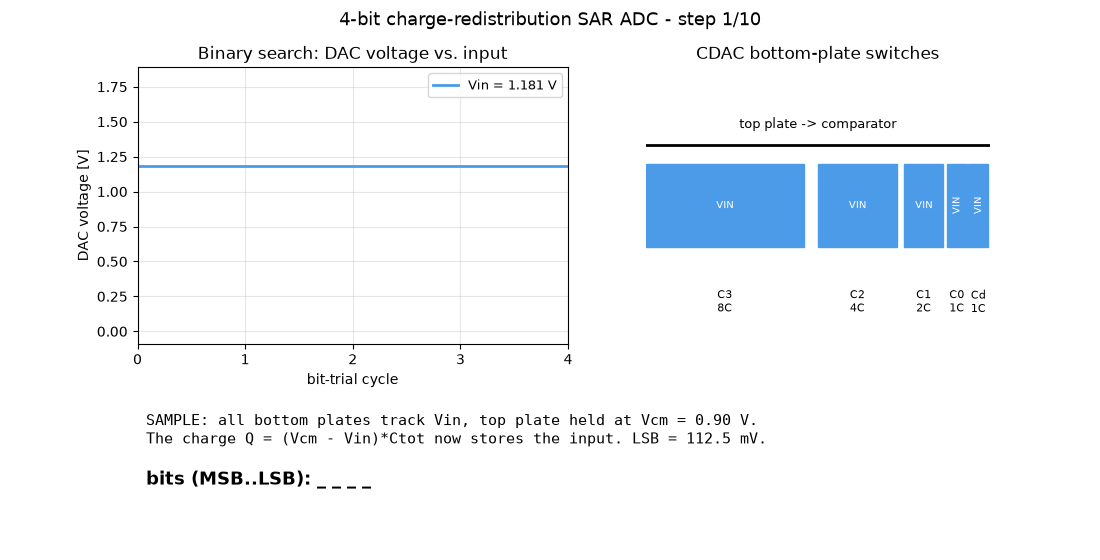

In [3]:
OUT.mkdir(parents=True, exist_ok=True)
vin_demo = round(0.6 * 2**BITS) * spec.lsb + 0.5 * spec.lsb
animate_conversion(SarModel(BITS, spec.vref), vin_demo, OUT / "sar_animation.gif")
Image(filename=str(OUT / "sar_animation.gif"))

## 3. Run the automated flow
`run_flow` executes all stages; each is explained in the following sections.
PDK characterization is cached in `build/char/` after the first run.

In [4]:
res = run_flow(spec, OUT, **FLOW_OPTS)

[   0.0s] 1/8 PDK characterization (A_VT, R_on, MIM)
[   0.0s] 2/8 sizing
[   0.0s] 3/8 netlist + single-conversion transient


[   9.6s] 4/8 comparator offset Monte Carlo (24 x 8 instances)


[  97.8s] 5/8 ramp test: 32 hits/code, transistor level


[ 348.1s] 6/8 sine test: 128-point coherent FFT, transistor level


[ 432.8s] 7/8 mismatch Monte Carlo: behavioral model x 1000 (+0 SPICE seeds)


[ 433.3s] 8/8 animation + report


[ 435.3s] done -> build/4bit


## 4. PDK characterization (ngspice, SKY130 `tt` / `tt_mm`)
No textbook constants are used. The flow measures:
* **A<sub>VT</sub>**: 200 mismatch instances per geometry of diode-connected nfet/pfet in one netlist; A<sub>VT</sub> = sqrt(2) sigma(V<sub>GS</sub>) sqrt(WL).
* **R<sub>on</sub> x W** of transmission gates (worst case over the input range) and of the NMOS/PMOS DAC drivers -
  at nominal conditions *and* at the worst corners (ss/-40 C, ss/125 C, tt/-10 % supply). A standard-V<sub>t</sub> gate
  passing mid-rail at ss/-40 C is 36x weaker than at tt (both devices barely on), so the generator compares
  standard and **low-V<sub>t</sub>** (`nfet/pfet_01v8_lvt`) gates and picks the better one for the sampling switches.
* **MIM capacitance** per area and per perimeter (AC simulation of three geometries), and the **MIM matching
  coefficient** read from the PDK model card (`sigma(dC/C) = 2.8 %/sqrt(WL)`).

In [5]:
c = res["char"]
display(Markdown(f'''
| quantity | value |
|---|---|
| A_VT nfet / pfet | {c["avt_n_mVum"]:.2f} / {c["avt_p_mVum"]:.2f} mV um |
| TG (Wn=1, Wp=2) R_on W, std, tt 27 C | {c["ron_tg_ohm_um"]/1e3:.2f} kOhm um |
| TG R_on W, worst corner: std / lvt | {c["ron_tg_worst_ohm_um"]["std"]/1e3:.1f} / {c["ron_tg_worst_ohm_um"]["lvt"]/1e3:.1f} kOhm um ({c["ron_worst_where"]["tg_std"]}) |
| NMOS / PMOS driver R_on W | {c["ron_n_ohm_um"]:.0f} / {c["ron_p_ohm_um"]:.0f} Ohm um |
| MIM density | {c["mim_ca_fF_um2"]:.3f} fF/um^2 + {c["mim_cp_fF_um"]:.3f} fF/um perimeter |
| MIM matching | {c["mim_match_pct_um"]} % um |
'''))


| quantity | value |
|---|---|
| A_VT nfet / pfet | 7.38 / 9.18 mV um |
| TG (Wn=1, Wp=2) R_on W, std, tt 27 C | 12.11 kOhm um |
| TG R_on W, worst corner: std / lvt | 434.9 / 7.4 kOhm um (ss -40C 1.80V) |
| NMOS / PMOS driver R_on W | 669 / 3095 Ohm um |
| MIM density | 2.000 fF/um^2 + 0.165 fF/um perimeter |
| MIM matching | 2.8 % um |


## 5. Specification-driven sizing
Each row is one design decision: the rule, the numbers that went in, and the result.

In [6]:
design = json.loads((OUT / "design.json").read_text())
display(Markdown(sizing_table_md(design)))

| block | rule | numbers | result |
|---|---|---|---|
| spec | LSB = Vref / 2^N | 1.8 V / 16 | **112.50 mV** |
| timing | Tclk = 1 / ((N + 2) * fs) | fs = 10 MS/s, 6 cycles | **16.67 ns (60.0 MHz)** |
| CDAC | sigma_DNL(mid-code) = sqrt(2^N - 1) * sigma_u <= DNL_3sigma / 3 | sigma_u <= 4.303 %, A_C = 2.8 %um | **side >= 0.65 um (matching)** |
| CDAC | kT/C: sqrt(kT / C_total) <= noise_lsb * LSB | C_total >= 0.0327 fF | **negligible at this resolution** |
| CDAC | Cu = Ca * s^2 + Cp * 4s (characterized MIM) | s = 2.00 um, limited by min. size | **Cu = 9.32 fF, C_total = 149.1 fF** |
| comparator | offset only shifts the transfer curve here (no DNL/INL): spec = offset error | 3 sigma_os <= 1.0 LSB | **sigma_os <= 37.50 mV** |
| comparator | sigma_os ~ A_VT / sqrt(W L) <= offset_3sigma * LSB / 3 | A_VT = 7.38 mVum, target 37.50 mV | **W L >= 0.039 um^2 -> W/L = 2.0/0.3 (est. 9.52 mV)** |
| comparator | pre-amplifier needed if W L > 20 um^2 (input cap / kick-back) | W L = 0.04 um^2 | **no - StrongARM alone** |
| comparator | tail = 1.5 W_in, latch = W_in / 2, reset / inverters fixed |  | **tail 3.0, nlatch 1.0, platch 1.0 um** |
| sampling | TG device flavour = lowest worst-case R_on W (ss/-40C, ss/125C, tt/-10% supply) | std: 434.9 kOhm um, lvt: 7.4 kOhm um | **lvt transistors** |
| sampling | tau = T_track / ln(2^N / settle_lsb); 1/4 bit switch, 3/4 top switch | T_track = 14.17 ns, tau <= 3406 ps | **R_unit <= 91.4 kOhm, R_top <= 17136 Ohm** |
| sampling | W_n = (R_on W)_TG,worst / R  (Wp = 2 Wn), bit-i switch = 2^i units | worst (R_on W) = 7.45 kOhm um (ss -40C 1.80V) | **unit TG 0.45/0.90 um, top TG 0.45/0.90 um** |
| DAC driver | tau = 0.45 Tclk / ln(2^N / settle_lsb), per unit cap (binary scaled) | tau <= 1803 ps, R_unit <= 96.8 kOhm | **unit NMOS 0.45 um, unit PMOS 0.45 um** |

## 6. Generated netlist and a single conversion
The testbench below is written by `sargen.netlist`. The SAR logic is built from SKY130 standard cells
(`sky130_fd_sc_hd` DFF with reset, OR, NAND/NOR sized by fan-out); only the clock phases come from ideal sources.
Watch the top plate: it jumps with every bit trial and converges back to V<sub>cm</sub>, the binary search in silicon.

Three switching-order rules keep the top plate inside the supply rails, so no switch junction is ever
forward-biased (each one was found by the flow's own simulations, see the git history):
1. **MSB first:** when sampling ends, the MSB plate goes to V<sub>ref</sub> immediately.
2. **Track, then ground:** the other plates keep tracking V<sub>in</sub> until the MSB has settled and only then go to
   ground. Grounding them first pulled the top plate to V<sub>cm</sub> - V<sub>in</sub> (-0.85 V, 7 missing codes at 8 bit);
   letting them float instead pushed it to V<sub>cm</sub> + V<sub>ref</sub> - V<sub>in</sub> (2.6 V, INL bow).
3. **Release before set:** a rejected bit returns to ground (trial ends at 0.92 T<sub>clk</sub>, decision latched at
   0.80 T<sub>clk</sub>) before the next bit is tried; otherwise the top plate glitches by one bit weight every cycle.

* SAR ADC 4-bit testbench (generated by sargen)
.lib /foss/pdks/sky130A/libs.tech/ngspice/sky130.lib.spice tt
.include /foss/pdks/sky130A/libs.ref/sky130_fd_sc_hd/spice/sky130_fd_sc_hd.spice
.temp 27.0
.option method=gear
.subckt strongarm inp inn clk qp qn vdd vss
XMt tail clk vss vss sky130_fd_pr__nfet_01v8 L=0.15 W=3 nf=1 ad=0.87 as=0.87 pd=6.58 ps=6.58 nrd=0.09667 nrs=0.09667 sa=0 sb=0 sd=0 mult=1 m=1
XMi1 xp inp tail vss sky130_fd_pr__nfet_01v8 L=0.3 W=2 nf=1 ad=0.58 as=0.58 pd=4.58 ps=4.58 nrd=0.145 nrs=0.145 sa=0 sb=0 sd=0 mult=1 m=1
XMi2 xn inn tail vss sky130_fd_pr__nfet_01v8 L=0.3 W=2 nf=1 ad=0.58 as=0.58 pd=4.58 ps=4.58 nrd=0.145 nrs=0.145 sa=0 sb=0 sd=0 mult=1 m=1
XMn1 outn outp xp vss sky130_fd_pr__nfet_01v8 L=0.15 W=1 nf=1 ad=0.29 as=0.29 pd=2.58 ps=2.58 nrd=0.29 nrs=0.29 sa=0 sb=0 sd=0 mult=1 m=1
XMn2 outp outn xn vss sky130_fd_pr__nfet_01v8 L=0.15 W=1 nf=1 ad=0.29 as=0.29 pd=2.58 ps=2.58 nrd=0.29 nrs=0.29 sa=0 sb=0 sd=0 mult=1 m=1
XMp1 outn outp vdd vdd sky130_fd_pr__pf

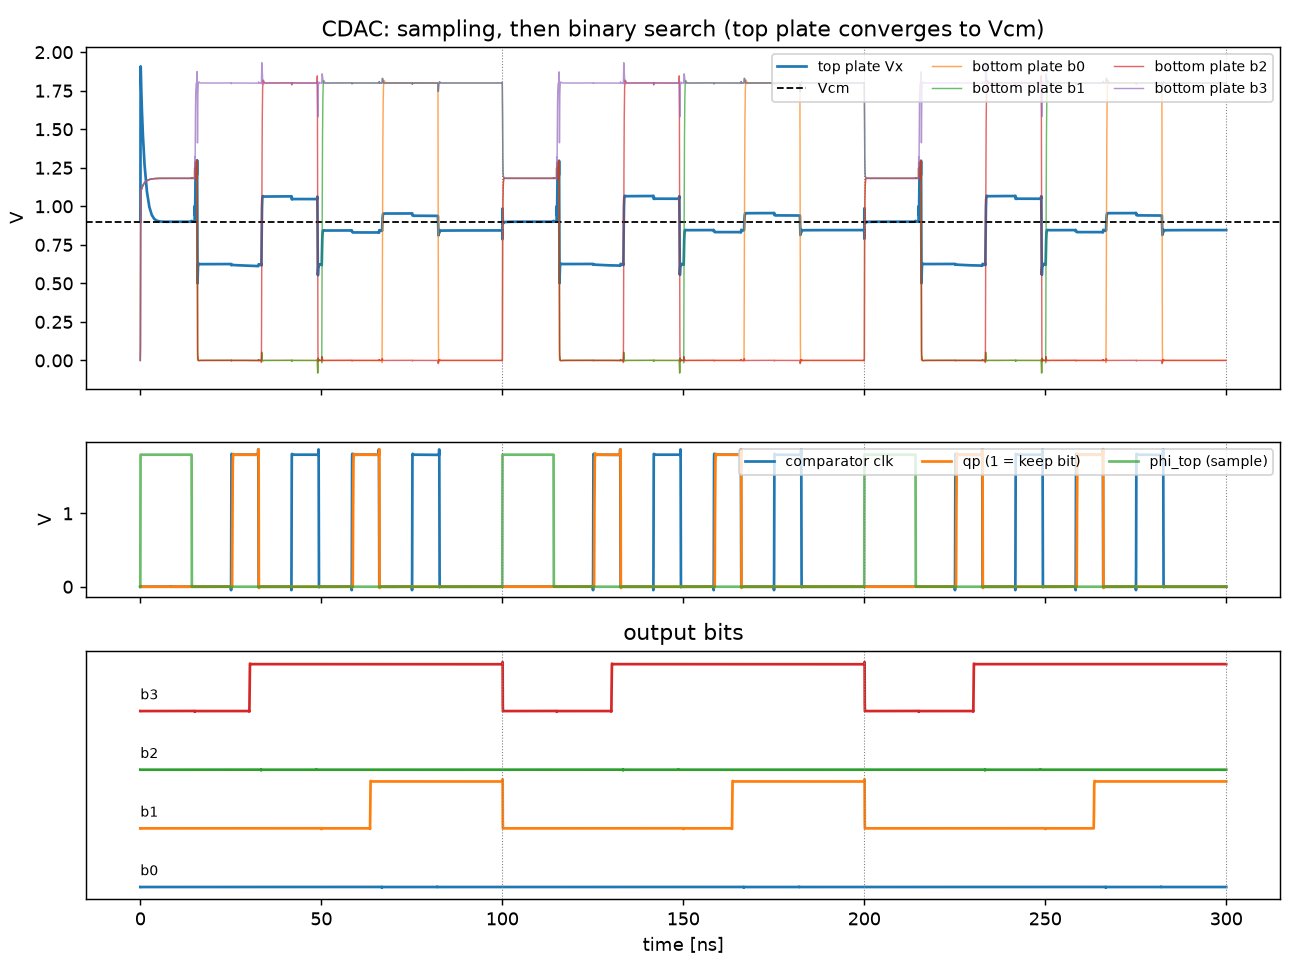

In [7]:
tb = (OUT / f"sar_adc_{BITS}b_tb.spice").read_text().splitlines()
print("\n".join(tb[:12] + ["..."] + [l for l in tb if l.startswith(("* ----", "abr", "aff"))][:20]))
print(f"\nVin = {res['single']['vin']:.4f} V -> code {res['single']['code']} (ideal {res['single']['ideal']})")
Image(filename=str(OUT / "waveforms.png"))

## 7. Comparator offset Monte Carlo
192 StrongARM instances with independent SKY130 mismatch are swept with a slow ramp. In this single-ended,
conventional-switching SAR the comparator offset only shifts the whole transfer curve (offset error); it does
not create DNL. That is why a small, fast comparator is enough at low resolution.

sigma_os = 8.64 mV  (0.077 LSB), mean = 0.83 mV, n = 192


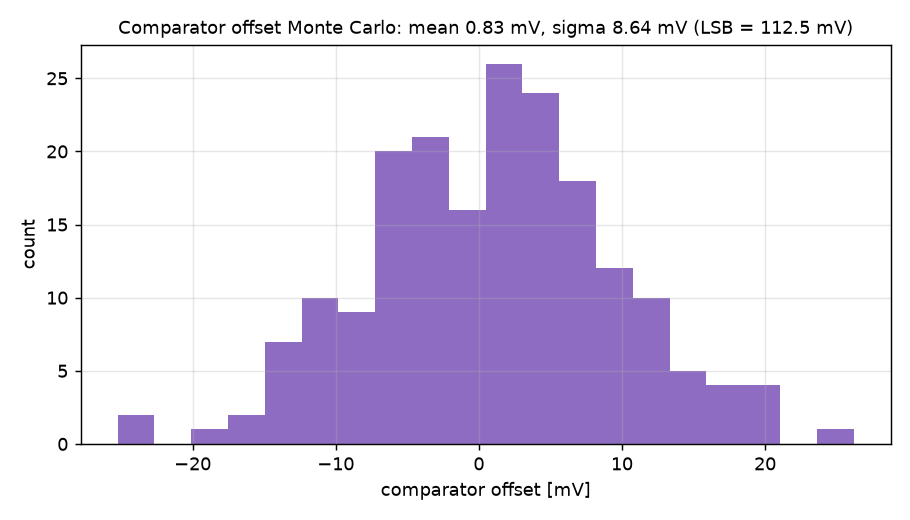

In [8]:
o = res["comparator_offset"]
print(f"sigma_os = {o['sigma']*1e3:.2f} mV  ({o['sigma']/spec.lsb:.3f} LSB), mean = {o['mean']*1e3:.2f} mV, n = {o['n']}")
Image(filename=str(OUT / "comparator_offset.png"))

## 8. Static linearity: ramp + code-density (histogram) test
A slow ramp that slightly over-drives both ends is applied to the transistor-level ADC. The number of hits per
code gives DNL; its running sum gives INL (end-point fit).

max|DNL| = 0.038 LSB, max|INL| = 0.062 LSB, missing codes = 0, offset = -0.122 LSB, gain error = -0.021 LSB


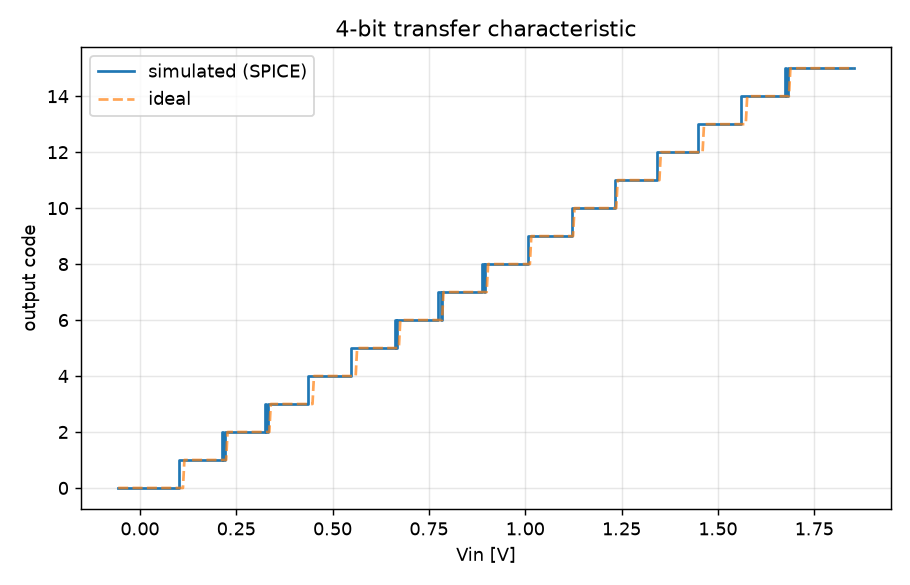

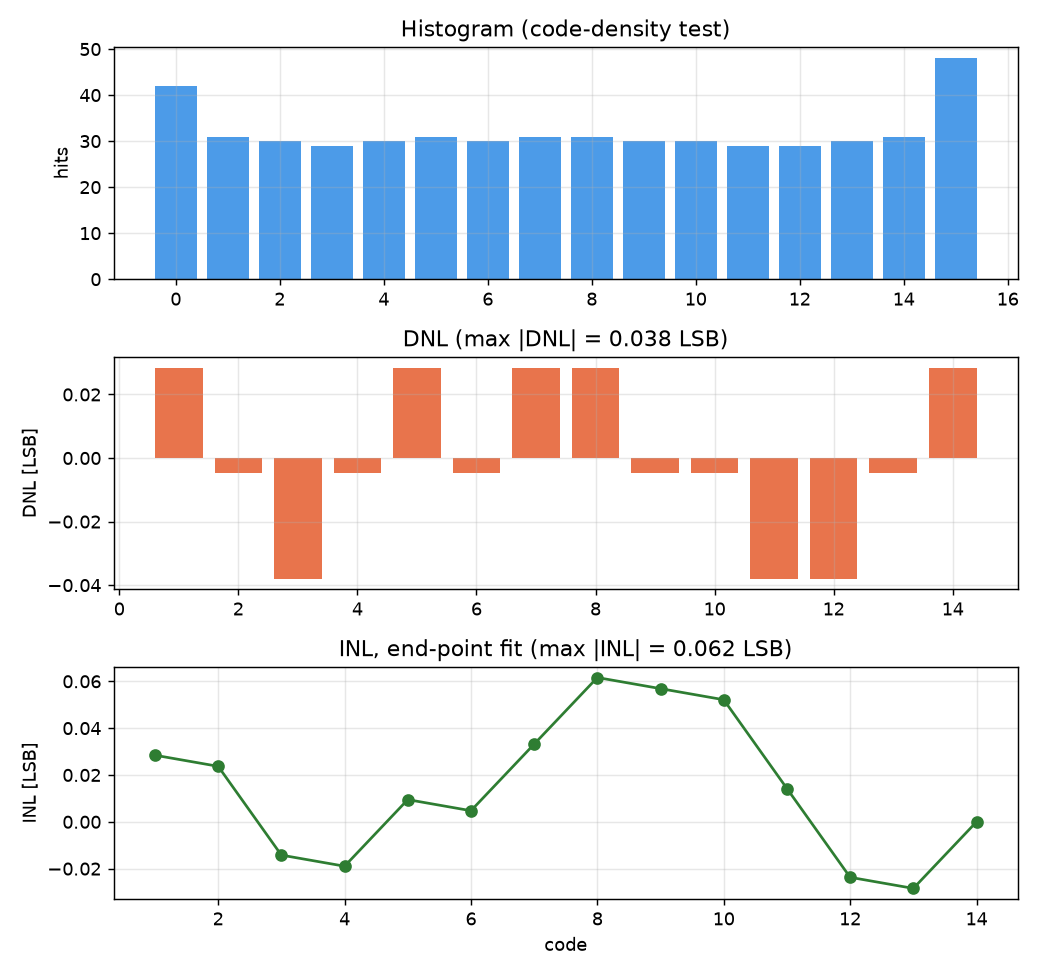

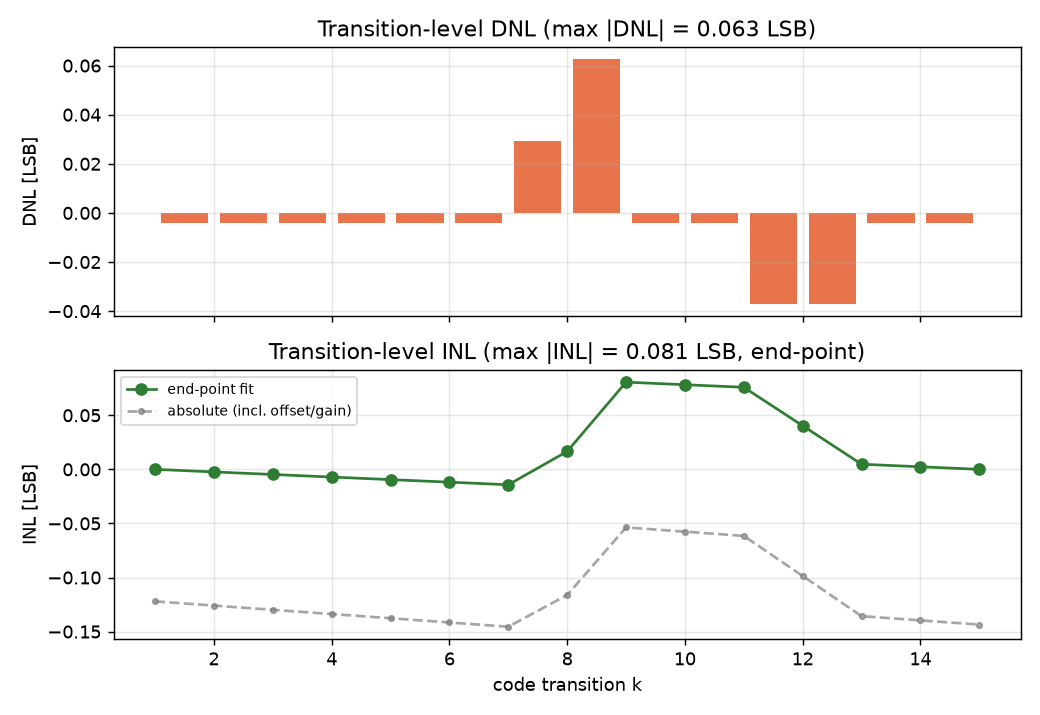

In [9]:
s = res["static"]
print(f"max|DNL| = {s['dnl_max']:.3f} LSB, max|INL| = {s['inl_max']:.3f} LSB, missing codes = {s['missing_codes']}, "
      f"offset = {s['offset_lsb']:.3f} LSB, gain error = {s['gain_error_lsb']:.3f} LSB")
display(Image(filename=str(OUT / "transfer.png")))
display(Image(filename=str(OUT / "inl_dnl_histogram.png")))
Image(filename=str(OUT / "inl_dnl_transitions.png"))

## 9. Dynamic performance: coherent FFT, ENOB
A full-scale sine with a prime number of cycles in the record (coherent sampling, no window) is converted at
transistor level. ENOB = (SNDR - 1.76 dB) / 6.02.

SNDR 25.58 dB, SFDR 34.7 dB, ENOB 3.96 bit (ideal 4-bit quantizer on the same samples: 3.97 bit)
Power 13.93 uW, 1.393 pJ/conv, Walden FoM 89.7 fJ/conv-step


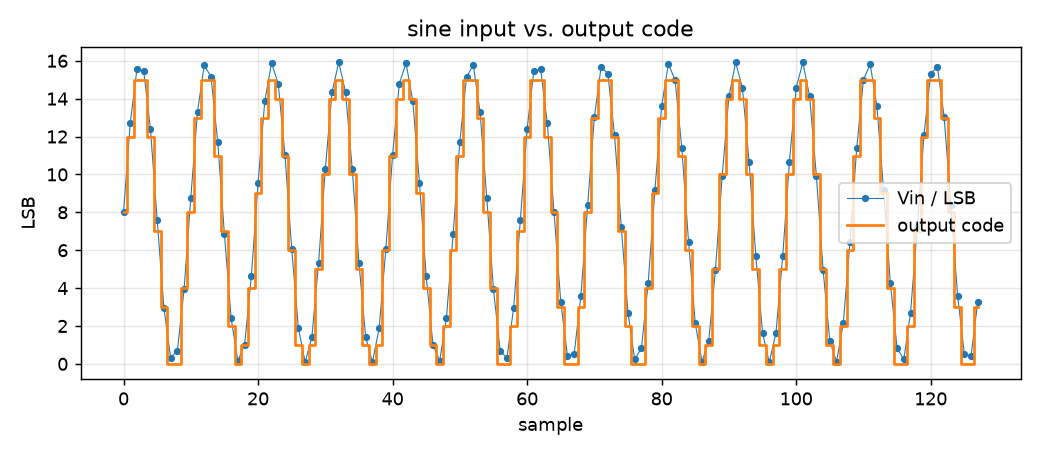

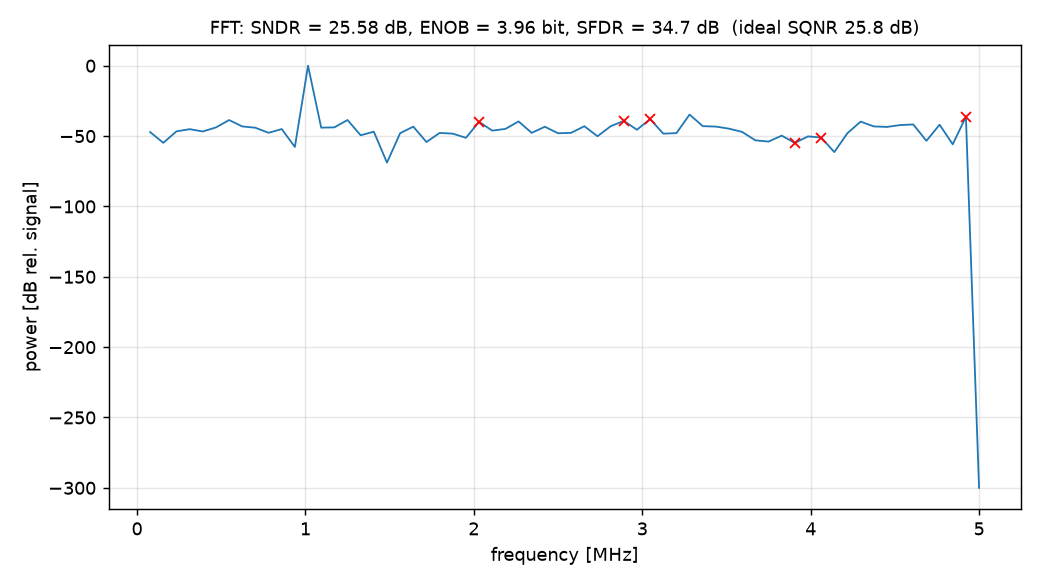

In [10]:
d, p = res["dynamic"], res["power"]
print(f"SNDR {d['sndr_db']:.2f} dB, SFDR {d['sfdr_db']:.1f} dB, ENOB {d['enob']:.2f} bit "
      f"(ideal {BITS}-bit quantizer on the same samples: {d['ideal_model_enob']:.2f} bit)")
print(f"Power {p['p_total']*1e6:.2f} uW, {p['energy_per_conv']*1e12:.3f} pJ/conv, Walden FoM {p['walden_fom_J']*1e15:.1f} fJ/conv-step")
display(Image(filename=str(OUT / "sine_samples.png")))
Image(filename=str(OUT / "fft.png"))

## 10. Yield: PDK-calibrated behavioral Monte Carlo
The behavioral model uses the *measured* unit-capacitor sigma (from the PDK MIM model) and comparator offset
sigma (section 7), so thousands of mismatch samples run in seconds.

1000 runs: 99th percentile DNL 0.130 LSB, INL 0.083 LSB, yield(DNL<0.5 LSB) = 100.0 %


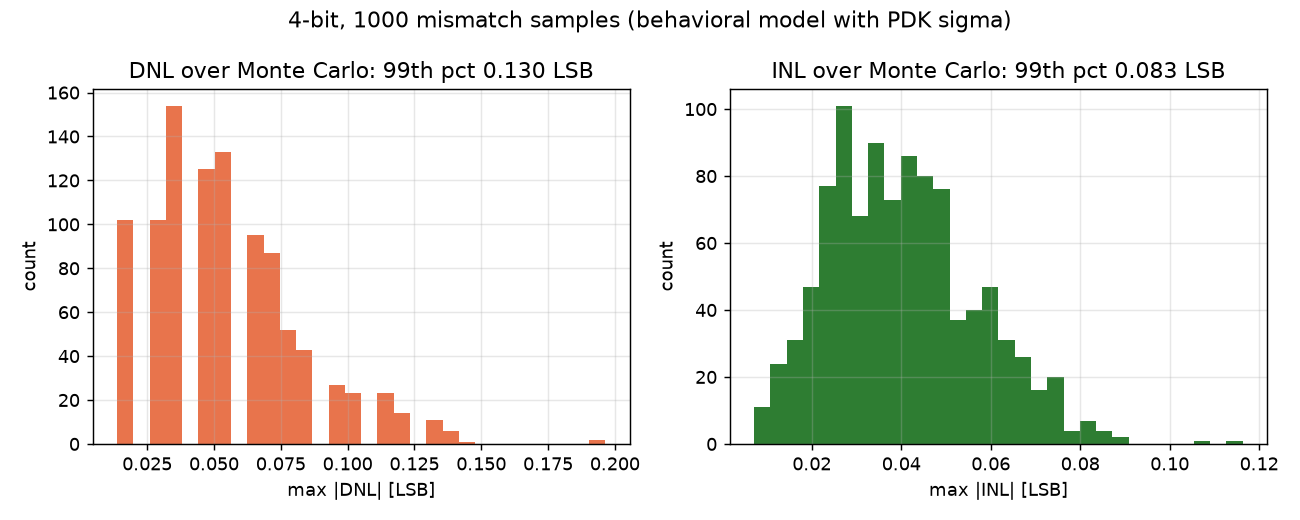

In [11]:
m = res["mc"]
print(f"{m['runs']} runs: 99th percentile DNL {m['dnl_p99']:.3f} LSB, INL {m['inl_p99']:.3f} LSB, "
      f"yield(DNL<0.5 LSB) = {m['yield_dnl_lt_0p5']*100:.1f} %")
Image(filename=str(OUT / "mc_linearity.png"))

## 11. One generator, 4 to 8 bits
The same code sized and simulated 4-, 6- and 8-bit converters at transistor level (8-bit: 2048-point ramp,
256-point FFT, about an hour on 11 cores). These long runs are not repeated inside the notebook; their small
result files live in `results/` and are regenerated with `python3 run_flow.py --bits N` and
`python3 collect_results.py`.

What changes with N is driven by the sizing rules: the unit capacitor grows once **MIM matching** (not kT/C) limits
mid-code DNL, the comparator input pair grows with the tighter offset target, and the top-plate switch grows with the
total array capacitance.

| bits | fs | enob | ideal_enob | sndr | dnl | inl | missing | offset | p_uw | e_pj | fom_fj | ctot_ff | cu_ff | w_in | mc_dnl_p99 | runtime_min |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 4 | 1e+07 | 3.96 | 3.97 | 25.6 | 0.0625 | 0.0806 | 0 | -0.122 | 13.9 | 1.39 | 89.7 | 149 | 9.32 | 2 | 0.13 | 6.16 |
| 6 | 1e+07 | 6.01 | 6.14 | 37.9 | 0.206 | 0.202 | 0 | -0.262 | 33.8 | 3.38 | 52.5 | 596 | 9.32 | 2.1 | 0.302 | 17.7 |
| 8 | 1e+07 | 7.94 | 8.05 | 49.6 | 0.129 | 0.224 | 0 | -0.81 | 187 | 18.7 | 76 | 4.19e+03 | 16.4 | 33.1 | 0.443 | 61.3 |


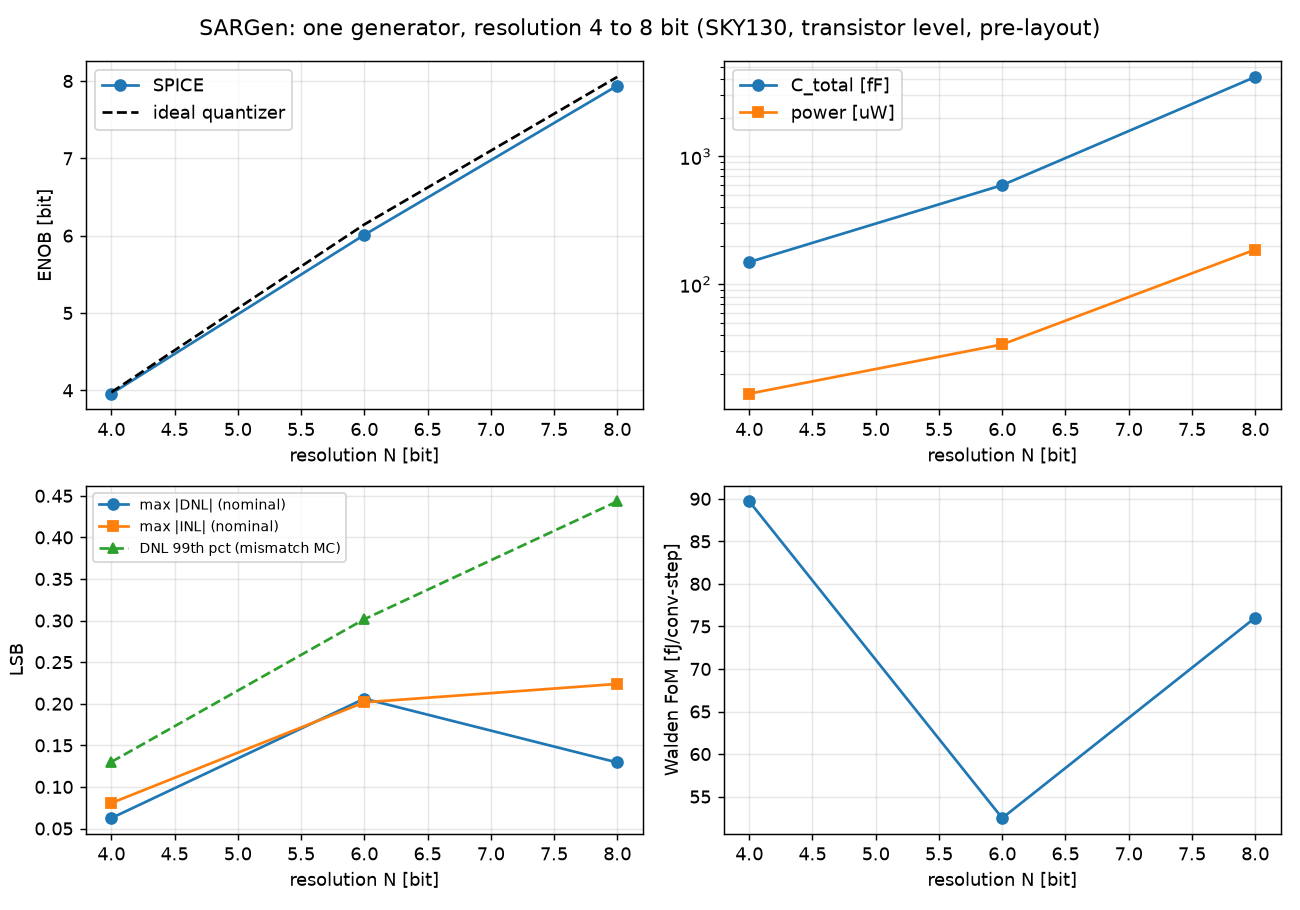

In [12]:
R = Path("results")
def show(p):
    p = Path(p)
    if p.suffix == ".png" and p.exists():
        display(Image(filename=str(p)))
    elif p.exists():
        display(Markdown(p.read_text()))
    else:
        print(f"({p} not generated yet)")
show(R / "scaling.md")
show(R / "scaling.png")

## 12. Robustness of the nominal 4-bit design
One **fixed** design (sized at `tt`, 27 C, 1.8 V) is re-simulated - not re-sized - across conditions.

**12a. Process corners x temperature x supply**

| point | corner | temp | vdd | enob | sndr_db | sfdr_db | f_in | dnl_max | inl_max | missing | dnl_t | inl_t | offset_lsb | gain_lsb | p_uw |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| tt -40C 1.80V | tt | -40 | 1.8 | 3.97 | 25.7 | 35.9 | 1.02e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 13.5 |
| tt +27C 1.80V | tt | 27 | 1.8 | 3.96 | 25.6 | 34.7 | 1.02e+06 | 0.0711 | 0.0995 | 0 | 0.129 | 0.0996 | -0.139 | 0.0117 | 13.9 |
| tt +125C 1.80V | tt | 125 | 1.8 | 3.97 | 25.7 | 35.9 | 1.02e+06 | 0 | 0 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 15.9 |
| ss -40C 1.80V | ss | -40 | 1.8 | 3.98 | 25.7 | 37 | 1.02e+06 | 0.0616 | 0.0569 | 0 | 0.0625 | 0.0569 | -0.0723 | 0.0117 | 13.6 |
| ss +27C 1.80V | ss | 27 | 1.8 | 3.97 | 25.7 | 36.9 | 1.02e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 14 |
| ss +125C 1.80V | ss | 125 | 1.8 | 3.98 | 25.7 | 36.4 | 1.02e+06 | 0.0616 | 0.0616 | 0 | 0.0625 | 0.0617 | -0.0723 | 0.0117 | 14.8 |
| ff -40C 1.80V | ff | -40 | 1.8 | 3.97 | 25.7 | 35.9 | 1.02e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 13.3 |
| ff +27C 1.80V | ff | 27 | 1.8 | 3.99 | 25.8 | 36.7 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 14.5 |
| ff +125C 1.80V | ff | 125 | 1.8 | 3.96 | 25.6 | 35 | 1.02e+06 | 0.183 | 0.183 | 0 | 0.195 | 0.185 | -0.271 | 0.145 | 23.5 |
| sf -40C 1.80V | sf | -40 | 1.8 | 3.96 | 25.6 | 33.9 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 13.4 |
| sf +27C 1.80V | sf | 27 | 1.8 | 3.97 | 25.6 | 34.8 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 14.1 |
| sf +125C 1.80V | sf | 125 | 1.8 | 3.98 | 25.7 | 34.7 | 1.02e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 15 |
| fs -40C 1.80V | fs | -40 | 1.8 | 3.97 | 25.7 | 35.7 | 1.02e+06 | 0.123 | 0.113 | 0 | 0.129 | 0.104 | -0.139 | 0.145 | 13.5 |
| fs +27C 1.80V | fs | 27 | 1.8 | 3.98 | 25.7 | 37.7 | 1.02e+06 | 0.128 | 0.128 | 0 | 0.129 | 0.128 | -0.139 | 0.0117 | 15.9 |
| fs +125C 1.80V | fs | 125 | 1.8 | 3.95 | 25.5 | 35.6 | 1.02e+06 | 0.237 | 0.279 | 0 | 0.262 | 0.285 | -0.404 | 0.277 | 31.1 |
| tt +27C 1.62V | tt | 27 | 1.62 | 3.98 | 25.7 | 37.4 | 1.02e+06 | 0.133 | 0.133 | 0 | 0.137 | 0.133 | -0.00586 | -0.0547 | 11.2 |
| tt +27C 1.98V | tt | 27 | 1.98 | 3.97 | 25.7 | 35.5 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.47e-15 | -0.0723 | -0.0547 | 17.3 |


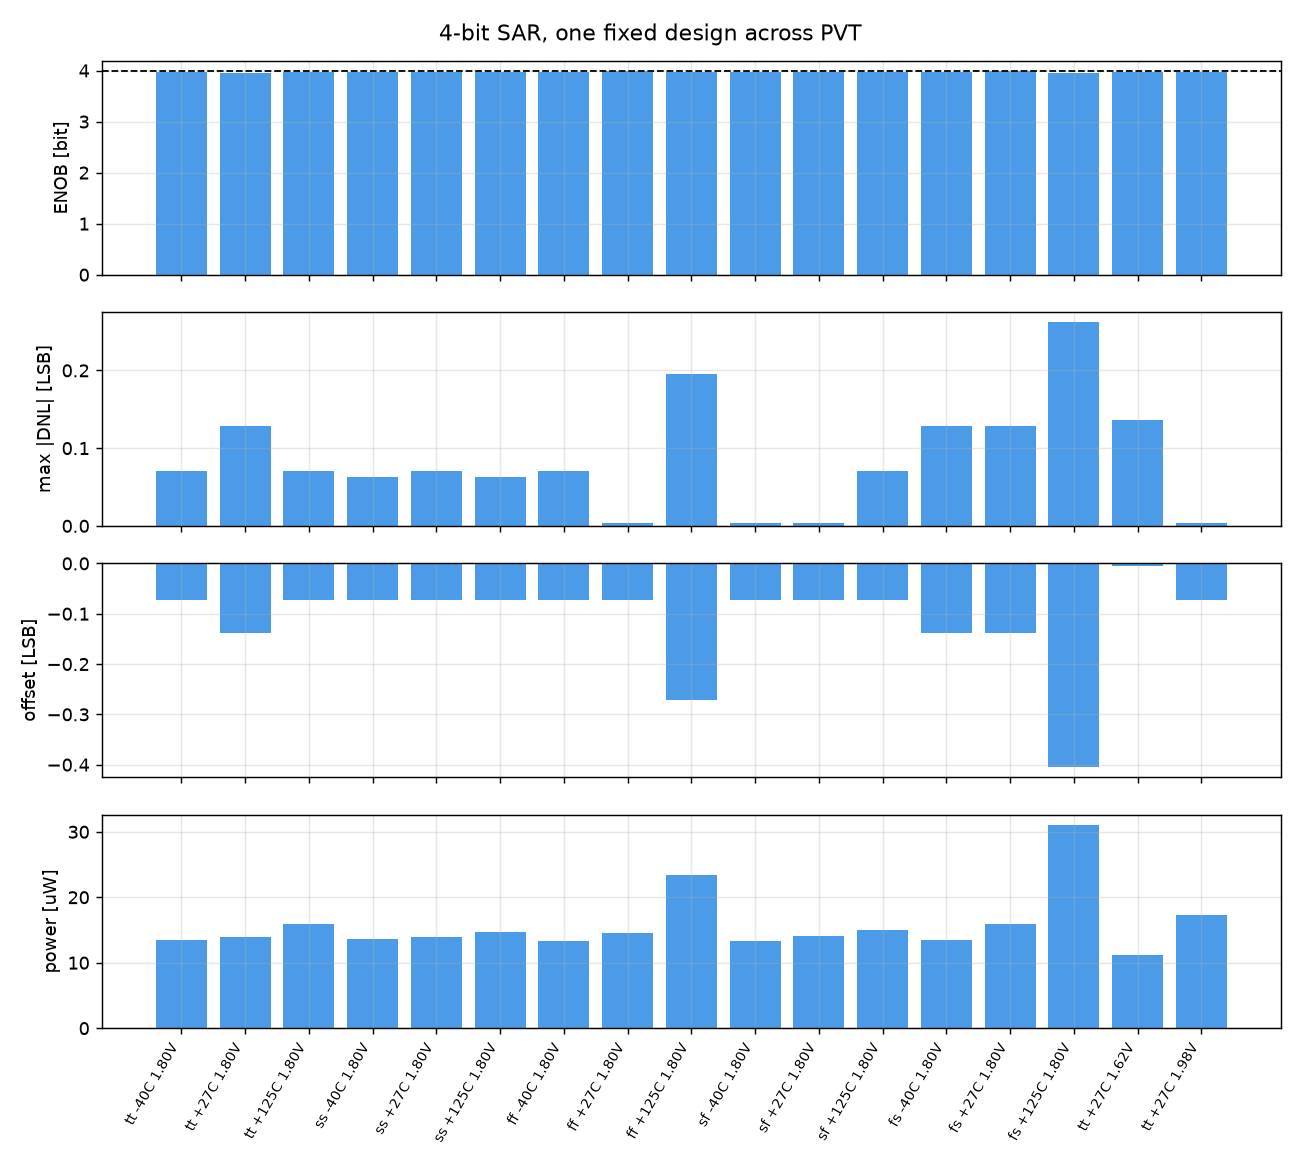

In [13]:
show(R / "4bit/sweeps/pvt_4b.md")
show(R / "4bit/sweeps/pvt_4b.png")

**12b. Input frequency up to Nyquist** - sampling-switch non-linearity would show up as falling ENOB.

In [14]:
show(R / "4bit/sweeps/fin_4b.md")

| point | f_in | enob | sndr_db | sfdr_db |
|---|---|---|---|---|
| fin=0.023 fs | 2.34e+05 | 3.95 | 25.5 | 35.9 |
| fin=0.102 fs | 1.02e+06 | 3.96 | 25.6 | 34.7 |
| fin=0.242 fs | 2.42e+06 | 3.99 | 25.8 | 37 |
| fin=0.367 fs | 3.67e+06 | 3.95 | 25.5 | 35.4 |
| fin=0.461 fs | 4.61e+06 | 3.94 | 25.5 | 36.4 |
| fin=0.492 fs | 4.92e+06 | 3.97 | 25.6 | 36.6 |


**12c. Sample rate** - the same design clocked faster until settling or comparator time runs out.

In [15]:
show(R / "4bit/sweeps/fs_4b.md")

| point | fs | enob | sndr_db | sfdr_db | f_in | dnl_max | inl_max | missing | dnl_t | inl_t | offset_lsb | gain_lsb | p_uw |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 10 MS/s | 1e+07 | 3.96 | 25.6 | 34.7 | 1.02e+06 | 0.0711 | 0.0995 | 0 | 0.129 | 0.0996 | -0.139 | 0.0117 | 13.9 |
| 20 MS/s | 2e+07 | 3.97 | 25.6 | 36.5 | 2.03e+06 | 0.0711 | 0.0995 | 0 | 0.0703 | 0.0996 | -0.139 | 0.0117 | 27.9 |
| 40 MS/s | 4e+07 | 3.99 | 25.8 | 37.3 | 4.06e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 56.2 |
| 80 MS/s | 8e+07 | 3.86 | 25 | 31.6 | 8.12e+06 | 0.0711 | 0.0806 | 0 | 0.0703 | 0.0427 | -0.0723 | 0.0117 | 114 |
| 160 MS/s | 1.6e+08 | nan | nan | nan | 1.62e+07 | nan | nan | 14 | nan | nan | nan | nan | 206 |


**12d. Comparator regeneration** - clock-to-output delay grows as tau * ln(1/dV) for small inputs; this sets the
metastability margin of the bit cycle.

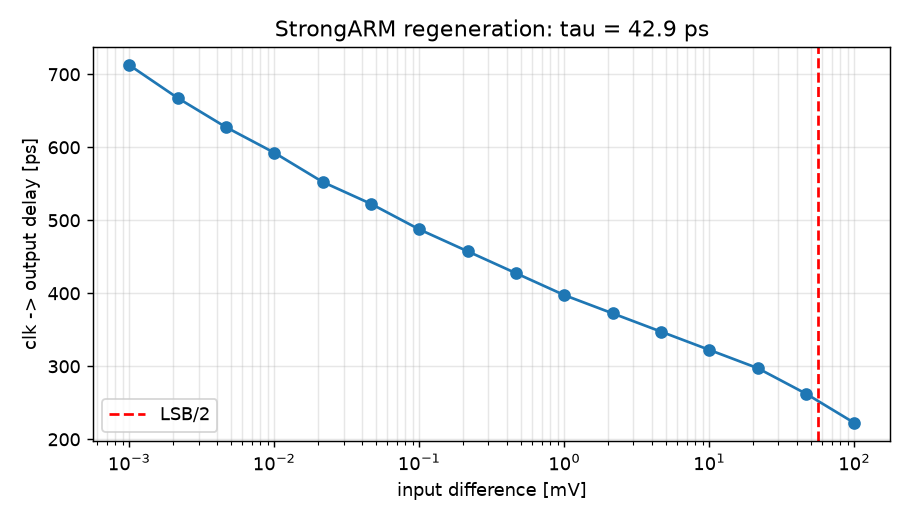

In [16]:
show(R / "4bit/sweeps/cmp_delay_4b.png")

**12e. Transistor-level mismatch vs. the behavioral model** - full SPICE ramps with SKY130 mismatch (`tt_mm`)
compared with the PDK-calibrated behavioral Monte Carlo of section 10 (red lines: individual transistor-level dies).

*Pitfall worth knowing:* each ramp is split into parallel ngspice runs. `set rndseed` in `.spiceinit` does **not**
give the same mismatch draws in every process, so the chunks silently became different dies and the stitched
transfer curve showed fake DNL steps exactly at the chunk boundaries. `.option seed=N` in the netlist is
reproducible; `sargen.spice` injects it.

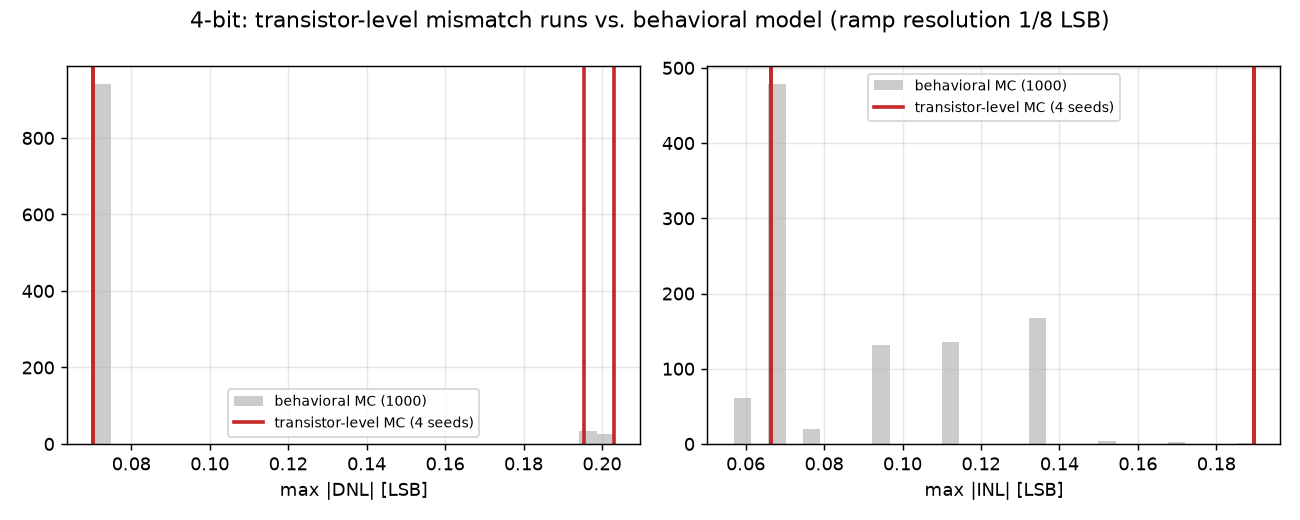

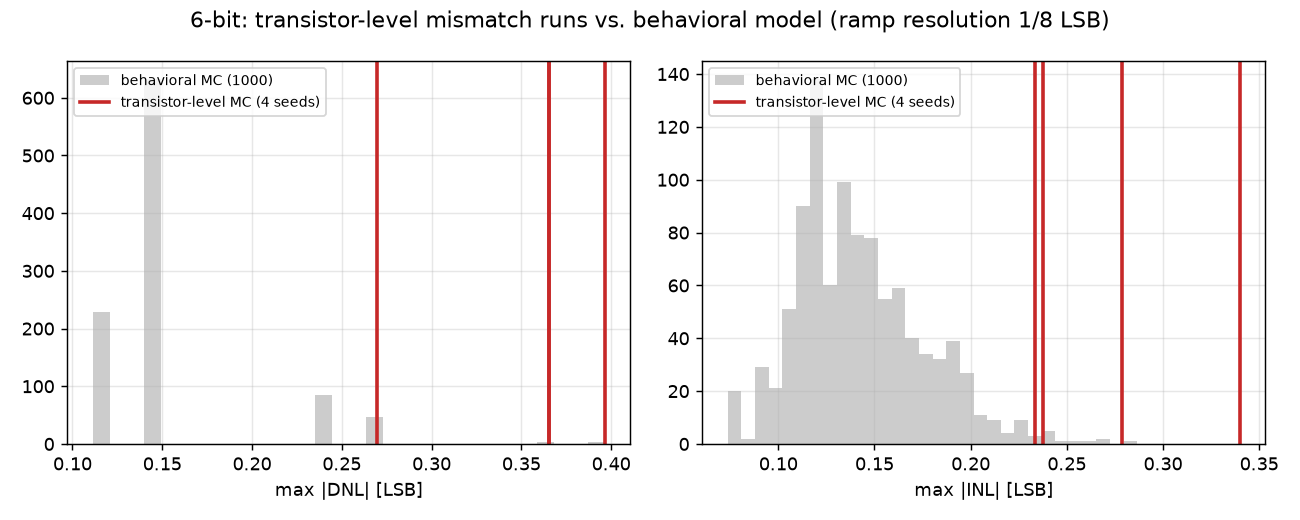

In [17]:
for n in (4, 6):
    show(R / f"{n}bit/sweeps/spice_mc_{n}b.png")

## 13. Summary

In [18]:
display(Markdown("## Results" + (OUT / "report.md").read_text().split("## Results")[1]))

## Results (transistor level, pre-layout)
| metric | value |
|---|---|
| ENOB (FFT, 1.016 MHz) | **3.96 bit** (ideal quantizer: 3.97) |
| SNDR / SFDR / THD | 25.58 dB / 34.7 dB / -32.0 dB |
| max DNL / INL (histogram) | 0.038 / 0.062 LSB |
| max DNL / INL (transition levels) | 0.063 / 0.081 LSB |
| missing codes | 0 |
| offset / gain error | -0.122 / -0.021 LSB |
| comparator offset sigma (MC, n=192) | 8.64 mV (0.077 LSB) |
| power (comparator + CDAC + switches + SAR logic cells) | 13.93 uW |
| energy / conversion | 1.393 pJ |
| Walden FoM | 89.7 fJ/conv-step |
| MC (1000 runs) 99th-pct DNL / INL | 0.130 / 0.083 LSB |
| MC yield (max DNL < 0.5 LSB) | 100.0 % |

Runtime: 435 s


## Limitations (pre-layout)
* Clock phases, V<sub>ref</sub> and V<sub>cm</sub> are ideal sources; their generation and buffering are not included in power.
* No layout parasitics yet (top-plate routing capacitance, MIM bottom-plate parasitics, wiring resistance).
* Comparator noise is not simulated (ngspice transient noise of devices); at 4-6 bits it is far below 1 LSB,
  at 8 bits it should be checked.
* Histogram/transition INL-DNL resolution is 1/hits LSB (1/32 at 4 bit, 1/8 at 8 bit).

## Roadmap
* **Automated layout** with gLayout: common-centroid MIM unit-cap array, StrongARM, binary-scaled switches.
* **DRC / LVS / PEX** (Magic, Netgen, KLayout) and post-layout re-run of sections 6-12 (pre vs. post table).
* Noise-aware comparator sizing and a preamplifier option for >8 bits.

## References
1. J. L. McCreary and P. R. Gray, "All-MOS charge redistribution analog-to-digital conversion techniques - Part I," IEEE JSSC, 1975.
2. M. J. M. Pelgrom, A. C. J. Duinmaijer, A. P. G. Welbers, "Matching properties of MOS transistors," IEEE JSSC, 1989.
3. B. Razavi, "The StrongARM latch," IEEE Solid-State Circuits Magazine, 2015.
4. IEEE Std 1241-2010, Terminology and test methods for analog-to-digital converters (code-density test, ENOB).
5. SkyWater SKY130 PDK, https://github.com/google/skywater-pdk
6. IIC-OSIC-TOOLS, https://github.com/iic-jku/IIC-OSIC-TOOLS